![scientisst-notebooks_top-banner](https://raw.githubusercontent.com/scientisst/notebooks/59632d3d477981a3b1cc12157e12bbdcdb45def8/_Resources/top-banner.png)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# <span style="color:#484848;"> LAB 3: RNA-seq Data Clustering: Temporal Profiling of Transcriptome of Early Cardiomyocyte Differentiation Derived From hiPSCs and hESCs

### <span style='color:#00aba1;'> Keywords </span>

`RNA-seq`, `Clustering`, `Cardiac differentiation`

Name:

IST Number:

### <span style='color:#00aba1;'> Notebook Info </span>

**Contributor(s):** Sofia Agostinho, Ana Fred, and Vicente Garção

**Date of creation:** 1/10/2023

**Last update:** 14/10/2023

### <span style="color:#00aba1;"> Description & Objectives </span>
The purpose of this lab is for understand how to use Clustering methods to gene expression data:

* Understand and analyse the clustering results both for the samples and genes dimension;
* Understand the advantages and disadvantages of each method;
* Understand the added benefits of ensemble clustering methods;
* Infer biological information from the clusters formed.

### <span style="color:#00aba1;"> Requirements </span>
In this section, the libraries required should be installed, using the command:

In [ ]:
!pip install fastcluster
!pip install biosppy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.0/194.0 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.4/149.4 kB 2.7 MB/s eta 0:00:00


and imported:

In [ ]:
# NumPy is the fundamental package for scientific computing with Python.
import numpy as np
# Matplotlib is a Python 2D plotting library
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
# Pandas is a library with easy-to-use data structures and data analysis tools
import pandas as pd
# Seaborn is a Python data visualization library based on matplotlib
import seaborn as sb
#  scikit-learn has simple and efficient tools for predictive data analysis
from sklearn import metrics
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import KMeans
# Fundamental algorithms for scientific computing in Python
import scipy
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
# This library provides Python functions for hierarchical clustering
import fastcluster
# Alternative to matplotlib
import plotly.express as px

import biosppy as bs
from biosppy.clustering import _life_time, kmeans, consensus_kmeans

# <span style="color:#00aba1;"> 1. Introduction </span>



## <div style="color:#00aba1;">  1.1 RNA-seq </div>

The RNA sequencing, RNA-seq for short, allows the extensive sequencing of all transcripts in a sample revolutionising the study of entire transcriptomes.
An RNA-seq experiment always starts with RNA extraction after which an RNA quality control check can be performed since it highly determines the overall success of the experiment [5]. The next steps are the fragmentation and reverse transcription to construct the library containing the fragments, or the so-called reads, to be sequenced [5].
At the end of the sequencing step, FASTQ files are created containing the sequences of each read and their quality score which serves to highlight possible anomalies in the previous steps [5]. Low quality reads should be excluded, but the overall quality of the reads should be as high as possible.
From the output of the sequencing step, reads must be aligned to a genome or transcriptome, but can also be assembled de novo, allowing for the study of unknown genes or even unannotated genomes [5].
To transform the mapped reads into gene expression data, all reads aligned to the same gene are counted [5]. From the resulting gene expression matrix, with quantitative expression for all genes present in the transcriptome, genes with too low counts can be filtered and the dataset should be normalised before bioinformatics and statistical analysis can be made.



<img src="C:/Users/sofia/Documents/MLB/23_24/lab3/_Resources/RNA-seq.png"/>


## <div style="color:#00aba1;">  1.2 Cardiac Differentiation </div>

hPSCs derived cardiomyocytes can be obtained through various experimental protocols. However, all these protocols rely on the temporal modulation of key signalling pathways that will be responsible for the transitions from a pluripotent state to a differentiated fate. The four major pathways involved in this differentiation are BMP, FGF, Wnt and TGFB/activin/NODAL [1].

Firstly, pluripotent cells are primed to a primitive streak-like stage, followed by a cardiac mesoderm stage by the activation of the previously mentioned pathways. This was initially done using factors such as transforming growth factor-beta (TGF-$\beta$), Activin A, bone morphogenetic protein 4 (BMP4) and the Wnt pathway activator Wnt3a. At a later stage of the protocol, the inhibition of the Wnt pathway with the antagonist DKK1 and adding VEGF and bFGF promotes cardiac specification allowing the production of cardiomyocytes [2].

The initial protocols were done using a culture medium supplemented with Fetal Bovine Serum, which, together with the high costs of the additional recombinant growth factors was not suitable for a larger scale production under GMP conditions.

New methodologies were introduced to overcome these problems and with the knowledge that the Wnt pathway has a temporal relevant impact on the differentiation, the initial supplements were replaced by a small molecule, CHIR99021, which activates the Wnt pathway, and a small molecule Wnt inhibitor such as IWR1, IWP2, IWP4, XAV939 and Ky02111 [2]. At the same time, differentiation protocols using chemically defined culture media were developed allowing now this differentiation to be performed in a more controlled environment.

## <div style="color:#00aba1;">  1.2 Clustering Methods </div>

#### <div style="color:#00a0e4">   1.2.1.   K-means </div>

The K-means algorithm is a partitional clustering method, that subdivides the samples into a predefined number of k clusters. Starting with k centroids randomly chosen from the data set, the algorithm iterates between a partitioning step, which consists in assigning genes to the cluster corresponding to the nearest centroid, and a centroid update step, which is the computation of the average of the genes in each cluster, until a stable partition is obtained.

The KMeans algorithm clusters data by trying to separate samples in K groups of equal variance, minimizing a criterion known as the inertia or within-cluster sum-of-squares.

#### <div style="color:#00a0e4">   1.2.2.   Hierarchical Agglomerative Clustering  </div>

Hierarchical Agglomerative Clustering algorithms organize data into a hierarchical structure, known as a dendrogram. In the beginning, each sample is considered to be a cluster and, progressively, the algorithms merges most similar clusters, until a single cluster, containing all the samples, is obtained. In
addition to a dissimilarity measure between samples, different definitions of dissimilarity between clusters lead to distinct clustering methods, such as
Single-link, Average-link or Complete-link. A data partition is obtained by cutting the dendrogram at a specific threshold or acording with a certain criteria.

#### <div style="color:#00a0e4">   1.2.3.   Evidence Accumulation </div>

Evidence Accumulation is an algorithm that combines the information created through the application of other clustering algorithms, taking each instance of clustering as independent evidence of data similarity.

It functions by repeatedly clustering with different methods, and for various different starting parameters, and creating an ensemble of different clusters created from the same data.

By doing so it is capable of avoiding pitfalls simpler algorithms fall into, as it can pull from a more complete and more contextualized data pool and distinguish real association between data, which should be repeatedly seen throughout the ensemble, from non-meaningful association, that happens due to the idiosyncrasies of the algorithm or simply due to happenstance, and should not be seen as often throughout the ensemble.

The distinction happens, more specifically, through a co-association matrix, where the information regarding how often or rarely each pair of elements of the dataset were grouped throughout the various starting clusters. Elements that often found themselves in the same cluster will have higher values in the corresponding matrix cell, and vice-versa.

Based on that matrix, a final partition is created, often by the application of single linkage Hierarchical Clustering, joining those that were often in the same partition throughout the ensemble.

The robustness of the method is highly dependent on the algorithms and parameters used to create the ensemble, therefore there can exist great variability in the quality of the results, depending on which and how many different techniques were used to create the co-association matrix [3].

#### <div style="color:#00a0e4">   1.2.4.   Explore More methods </div>

At the end you may explore different clustering methods not not presented here and discuss the obtained results (optional). You may use the ones implemented here: https://scikit-learn.org/stable/modules/clustering.html#clustering

# <span style="color:#00aba1;"> 2. Load and Check Data </span>

In this lab we will analyse the temporal changes in transcriptome during cardiac differentiation. 4 cell lines were used, 2 hiPSC lines (C15 and C20) and 2 hESC lines (H1 and H9) at 4 stages: pluripotent stem cells (day 0), mesoderm (day 2), cardiac mesoderm (day 4), and differentiated cardiomyocytes (CM).

We have data files for this work containing the gene expression data for the 32 samples. For the handling of this file pandas Python packages will be used.

In [ ]:
# Load the preprocessed data
Data=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/_Resources/genes_clust3.csv', header=0, index_col=0)
samp_data=Data.transpose(copy=True)

In [ ]:
# Check data
Data

,H1_day0_0,H1_day0_1,H1_day2_0,H1_day2_1,H1_day4_0,H1_day4_1,H1_CM_0,H1_CM_1,H9_day0_0,H9_day0_1,...,C15_CM_0,C15_CM_1,C20_day0_0,C20_day0_1,C20_day2_0,C20_day2_1,C20_day4_0,C20_day4_1,C20_CM_0,C20_CM_1
RNA45S5,7.922191,13.039664,-6.525964,-6.525964,-6.525964,-6.525964,11.085284,10.897702,-6.525964,-6.525964,...,-6.525964,-6.525964,-6.525964,-6.525964,11.286339,12.849901,-6.525964,-6.525964,9.152053,8.933727
SNORD9,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,15.151264,-3.784286,-3.784286,-3.784286,...,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,-3.784286,13.468952
MYH7,-0.407114,-3.504845,-4.588821,-3.890169,-4.588821,-4.588821,11.547407,11.897186,-4.588821,-4.588821,...,12.283601,12.521785,-4.588821,-4.588821,-4.588821,-4.588821,-4.588821,-4.588821,11.680463,11.943692
SNORA32,7.050883,-5.830047,-5.830047,-5.830047,-5.830047,-5.830047,9.438297,10.303476,-5.830047,-5.830047,...,8.031447,9.593226,6.446156,-5.830047,-5.830047,-5.830047,-5.830047,-5.830047,6.214101,7.851532
SNORD89,5.989798,7.362636,6.585851,-6.603229,7.995387,-6.603229,-6.603229,-6.603229,6.323865,-6.603229,...,7.999649,-6.603229,5.275450,-6.603229,-6.603229,5.893956,-6.603229,6.914760,6.197824,7.401132
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PNPO,-1.029853,-1.355291,-2.187723,-3.356078,-2.271371,-2.396141,-2.862080,-2.553738,0.478168,0.428913,...,1.864826,1.545200,0.692105,0.540792,0.873919,0.503299,1.103972,0.744877,1.095798,1.107030
CBX7,1.072521,0.833177,-2.229119,-1.494102,-1.072359,-0.633749,1.345514,1.030734,-0.318342,0.459393,...,1.807261,1.804114,0.247576,0.678866,-0.870045,-1.690464,0.121347,-0.326841,1.472857,1.818615
HERC3,-0.950721,-0.669166,0.495758,0.362398,-1.708478,-0.980298,1.783418,1.994922,-0.888631,-0.672380,...,2.643680,2.851485,-1.638025,-1.152662,-1.368599,-2.089348,-1.043954,-1.203338,1.577082,1.917357
URB1-AS1,-0.259192,-1.430206,-2.418054,-2.135895,-2.444692,-2.529710,0.292750,1.409932,-0.949217,0.566039,...,1.919659,2.149083,1.004351,1.599759,-1.519258,0.320941,0.374605,0.698150,1.314511,1.314971


In [ ]:
# check samp_data
samp_data

,RNA45S5,SNORD9,MYH7,SNORA32,SNORD89,MYL2,SCARNA22,MYL4,RNU4ATAC,MYH6,...,C18orf32,RNASE4,TMEM139,DUSP8,PCDHB17P,PNPO,CBX7,HERC3,URB1-AS1,PDZK1
H1_day0_0,7.922191,-3.784286,-0.407114,7.050883,5.989798,-4.095126,-5.871687,-4.727046,5.076991,-1.871293,...,0.351285,0.636447,0.433818,-2.410929,-1.105471,-1.029853,1.072521,-0.950721,-0.259192,-2.111479
H1_day0_1,13.039664,-3.784286,-3.504845,-5.830047,7.362636,-1.543256,-5.871687,-7.436747,-8.398894,-4.614500,...,-0.865853,0.953590,-0.119012,-3.185941,-0.955483,-1.355291,0.833177,-0.669166,-1.430206,-1.423448
H1_day2_0,-6.525964,-3.784286,-4.588821,-5.830047,6.585851,-4.095126,6.891894,-6.013894,3.102704,-4.259757,...,-1.726747,-1.331053,-1.628737,0.399762,0.106576,-2.187723,-2.229119,0.495758,-2.418054,-0.371249
H1_day2_1,-6.525964,-3.784286,-3.890169,-5.830047,-6.603229,-4.095126,-5.871687,-4.669976,4.931308,-3.905050,...,-1.188237,-0.919983,-1.107901,0.734855,-1.094292,-3.356078,-1.494102,0.362398,-2.135895,1.658034
H1_day4_0,-6.525964,-3.784286,-4.588821,-5.830047,7.995387,-4.095126,-5.871687,0.829082,5.296356,-3.629461,...,-0.488218,-2.094933,-0.365961,-1.460434,-0.634295,-2.271371,-1.072359,-1.708478,-2.444692,1.122184
H1_day4_1,-6.525964,-3.784286,-4.588821,-5.830047,-6.603229,-4.095126,-5.871687,1.515598,4.721590,-2.359071,...,-1.064732,-0.762601,-0.878512,-0.966120,1.044351,-2.396141,-0.633749,-0.980298,-2.529710,1.325651
H1_CM_0,11.085284,15.151264,11.547407,9.438297,-6.603229,12.073438,-5.871687,8.296420,7.129392,9.533486,...,2.001667,1.636627,2.525631,1.597007,1.790021,-2.862080,1.345514,1.783418,0.292750,-1.343573
H1_CM_1,10.897702,-3.784286,11.897186,10.303476,-6.603229,11.966705,-5.871687,8.685731,5.439039,9.926278,...,2.528984,2.287339,2.628645,0.429448,1.164347,-2.553738,1.030734,1.994922,1.409932,-1.856497
H9_day0_0,-6.525964,-3.784286,-4.588821,-5.830047,6.323865,-1.920905,7.087907,-7.940191,-8.398894,-5.176432,...,-0.707555,-0.598274,0.039776,-2.446800,-2.556535,0.478168,-0.318342,-0.888631,-0.949217,-0.973076
H9_day0_1,-6.525964,-3.784286,-4.588821,-5.830047,-6.603229,-4.095126,5.242029,-6.576470,4.115132,-4.094995,...,0.501415,-0.150653,0.361804,-2.033518,-2.343046,0.428913,0.459393,-0.672380,0.566039,-1.465250


# <span style="color:#00aba1;"> 3. Clustering </span>

## <span style="color:#00aba1;"> 3.1. Hierarchical Clustering for sample hierarchy inference</span>

We will start by using Euclidean distance and test single and complete linkage. We will try to extract 4 clusters from the resulting hierarchies and evaluate the resulting partition using internal indexes.

Then Pearson correlation-based distance will be used and the results should be compared.

### 3.1.1 - Euclidean Distance, Complete & Single Linkage

In [ ]:
def hierarchical_partition(linkage_matrix, criterion, n):
    """
    Performs hierarchical partitioning on a given linkage matrix.

    Parameters:
        linkage_matrix (ndarray): The linkage matrix obtained from hierarchical clustering.
        criterion (str): The criterion for partitioning. It can be either 'maxcluster' or 'life_time'.
        n (float): Number of clusters to form or life time if 0.

    Returns:
        threshold: Float that corresponds to the threshold to form n number of clusters.
        labels: An array of labels indicating the cluster assignments for each sample.
    """
    if  criterion == 'maxcluster':
        th=((linkage_matrix[-n,2]+linkage_matrix[-(n-1),2])/2)
        labels = fcluster(linkage_matrix, n, criterion='maxclust')

    if  criterion == 'life_time':
        N = (len(linkage_matrix)+1)

        if N < 3:
            raise ValueError("The number of objects N must be greater then 2.")

        # compute differences from Z distances
        df = np.diff(linkage_matrix[:, 2])
        # find maximum difference
        idx_max = np.argmax(df)
        mx_dif = df[idx_max]
        # find minimum difference
        mi_dif = np.min(df[np.nonzero(df != 0)])


        # find threshold link distance
        th_link = linkage_matrix[idx_max, 2]
        # links above threshold
        idxs = linkage_matrix[np.nonzero(linkage_matrix[:, 2] > th_link)[0], 2]
        #number of links above threshold +1 = number of clusters and singletons
        cont = len(idxs) + 1

        # condition (perceber melhor)
        if mi_dif != mx_dif:
            if mx_dif < 2 * mi_dif:
                cont = 1

        if cont > 1:
            labels = fcluster(linkage_matrix, cont, 'maxclust')
        else:
            labels = np.arange(N, dtype='int')


        th = ((linkage_matrix[idx_max, 2]+linkage_matrix[idx_max+1,2])/2)

    return {'threshold':th, 'samples_labels':labels}

In [ ]:
#Complete Linkage
complete_linkage=linkage(samp_data, method='complete', metric='euclidean', optimal_ordering=True)
complete_partition=hierarchical_partition(complete_linkage, criterion='maxcluster', n=4)

#Single Linkage
single_linkage=linkage(samp_data, method='single', metric='euclidean', optimal_ordering=True)
single_partition=hierarchical_partition(single_linkage, criterion='maxcluster', n=4)

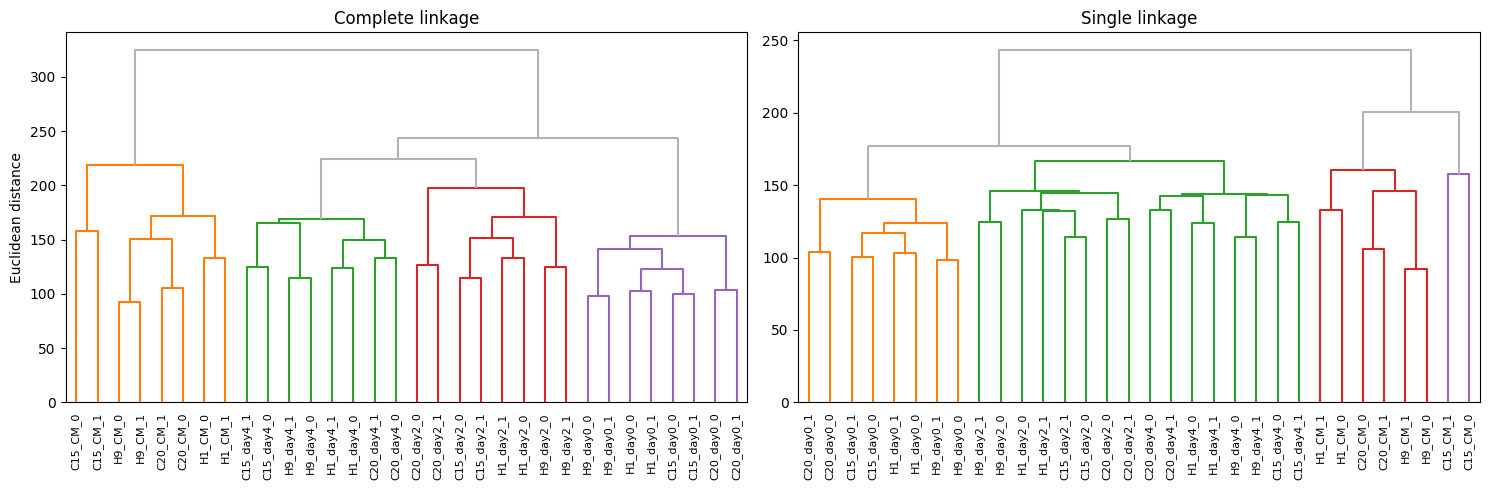

In [ ]:
#Dendrogram plots side by side
f= plt.figure()
f.set_figwidth(15)
f.set_figheight(5)
ax1=plt.subplot(121)
plt.title('Complete linkage')
plt.ylabel('Euclidean distance')
dn=dendrogram(Z=complete_linkage, color_threshold=complete_partition['threshold'], labels=samp_data.index, above_threshold_color='#b3b3b3', leaf_rotation=90)
ax2= plt.subplot(122)
plt.title('Single linkage')
dn=dendrogram(Z=single_linkage, color_threshold=single_partition['threshold'], labels=samp_data.index, above_threshold_color='#b3b3b3', leaf_rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# Partition internal evaluation
print('Complete Linkage evaluation')
print(f"silhouette score:{silhouette_score(samp_data, complete_partition['samples_labels'], metric='euclidean')}")
print(f"Davies-Bouldin Index:{davies_bouldin_score(samp_data,  complete_partition['samples_labels'])}")

print('Single Linkage evaluation')
print(f"silhouette score:{silhouette_score(samp_data, single_partition['samples_labels'], metric='euclidean')}")
print(f"Davies-Bouldin Index:{davies_bouldin_score(samp_data,  single_partition['samples_labels'])}")

Complete Linkage evaluation
silhouette score:0.28417083011483224
Davies-Bouldin Index:1.3201095365065432
Single Linkage evaluation
silhouette score:0.25034154156390676
Davies-Bouldin Index:1.209332381278724


### 3.1.2 - Pearson Correlation based Distance, Complete & and Single Linkage

In [ ]:
# Complete linkage
complete_linkage=linkage(samp_data, method='complete', metric='correlation', optimal_ordering=True)
complete_partition=hierarchical_partition(complete_linkage, criterion='maxcluster', n=4)

# Single linkage
single_linkage=linkage(samp_data, method='single', metric='correlation', optimal_ordering=True)
single_partition=hierarchical_partition(single_linkage, criterion='maxcluster', n=4)

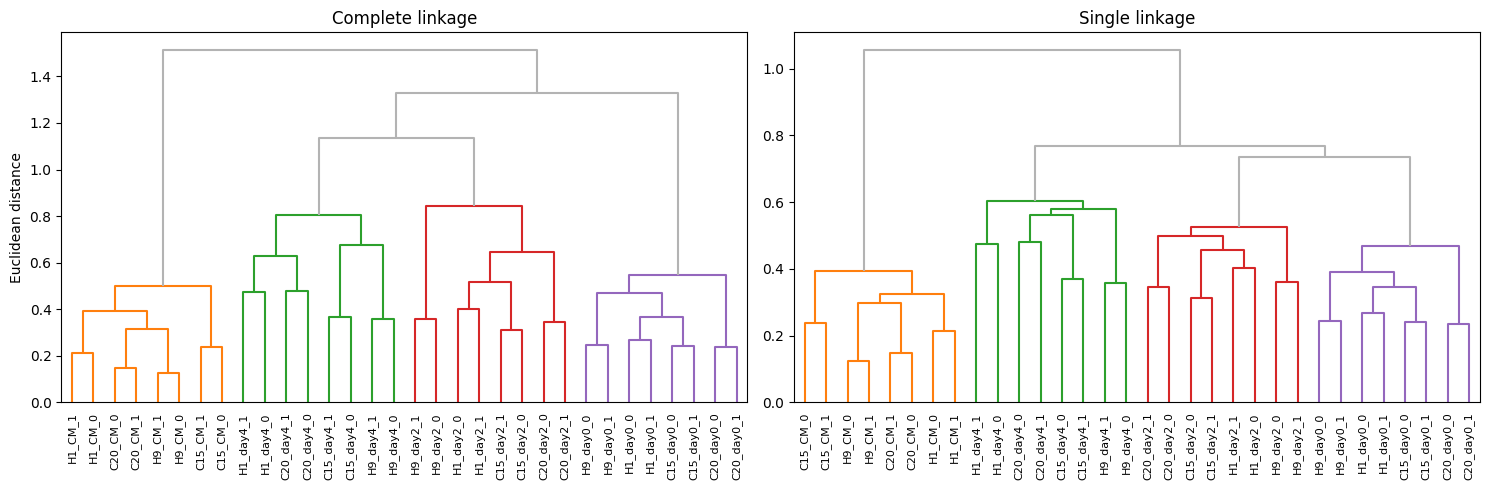

In [ ]:
#Dendrogram plots side by side
f= plt.figure()
f.set_figwidth(15)
f.set_figheight(5)
ax1=plt.subplot(121)
plt.title('Complete linkage')
plt.ylabel('Euclidean distance')
dn=dendrogram(Z=complete_linkage, color_threshold=complete_partition['threshold'], labels=samp_data.index, above_threshold_color='#b3b3b3', leaf_rotation=90)
ax2= plt.subplot(122)
plt.title('Single linkage')
dn=dendrogram(Z=single_linkage, color_threshold=single_partition['threshold'], labels=samp_data.index, above_threshold_color='#b3b3b3', leaf_rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# Partition internal evaluation
print('Complete Linkage evaluation')
print(f"Silhouette score:{silhouette_score(samp_data, complete_partition['samples_labels'], metric='euclidean')}")
print(f"Davies-Bouldin Index:{davies_bouldin_score(samp_data,  complete_partition['samples_labels'])}")

print('Single Linkage evaluation')
print(f"Silhouette score:{silhouette_score(samp_data, single_partition['samples_labels'], metric='euclidean')}")
print(f"Davies-Bouldin Index:{davies_bouldin_score(samp_data,  single_partition['samples_labels'])}")

Complete Linkage evaluation
Silhouette score:0.28417083011483224
Davies-Bouldin Index:1.3201095365065432
Single Linkage evaluation
Silhouette score:0.28417083011483224
Davies-Bouldin Index:1.3201095365065432


> ✏️ *QUESTIONS:*
> -  Considering the Euclidean linkage, explain the results obtained for the single linkage and complete linkage, having in mind the underlying concept of each algorithm and the results from the internal evaluation.
> - Explain the differences seen with the application of the Pearson correlation distance. In which situation do you envision this distance to be most suitable?
> - Explain the results obtained for the internal scores and the Pearson Correlation clusters.

> ✨ *Bonus:*
> - Try a different combination of metrics, and methods or even test the lifetime criteria!

Your answer goes here...

## <span style="color:#00aba1;"> 3.2. Gene clustering</span>

Now we will perform gene clustering. To do so, 2 methods will be tested, K-Means and Evidence Acumulation.
The resulting clusters will also be analysed for their biological relevance

A common way to visualise gene expression is with heatmaps or hierarchical bi-clustering heatmaps.

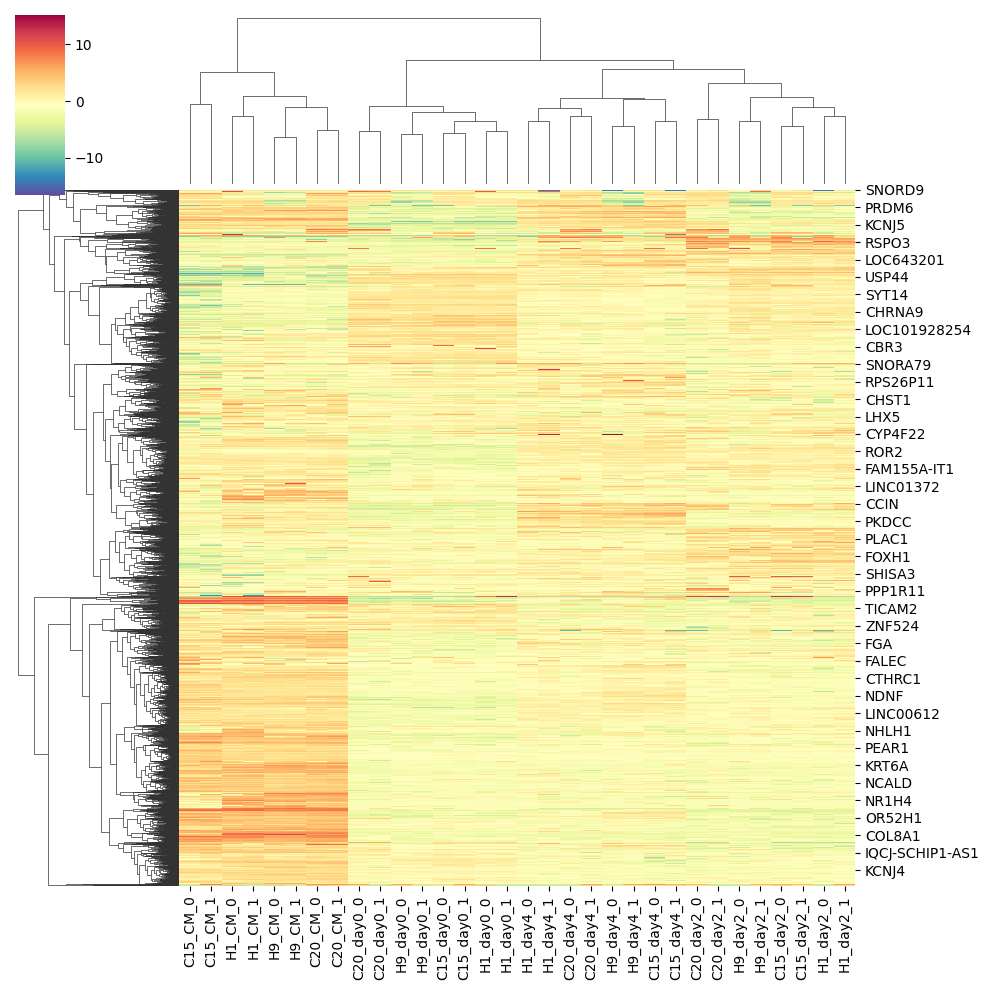

In [ ]:
sb.clustermap(Data,method='complete', metric='euclidean', cmap='Spectral_r', dendrogram_ratio=0.2)

> ✏️ *QUESTIONS:*
> -  Considering the heatmap above and your previous knowledge of biology what is the minimum number of gene clusters you expect to have?

Your answer goes here...

## <span style="color:#00aba1;"> 3.3. K-Means for gene clustering</span>

As already explained, K means receives as input the number of clusters, and so, this parameter should be carefully determined.
To do so we will use the elbow method.

In [ ]:
from numpy.ma.core import empty
range_n_clusters = range(1, 11)
sse = []
optimal_k=[]
for n_clusters in range_n_clusters:
   #iterating through cluster sizes
   kmeans_model = KMeans(n_clusters = n_clusters, random_state=42, n_init='auto')
   cluster_labels = kmeans_model.fit_predict(Data)
   #Finding the average SSE and the optimal_k
   # Inertia: Sum of distances of samples to their closest cluster center
   print("For n_clusters =", n_clusters , " the SSE is:", kmeans_model.inertia_ )
   sse.append(kmeans_model.inertia_)

For n_clusters = 1  the SSE is: 813876.5487854987
For n_clusters = 2  the SSE is: 615080.482523681
For n_clusters = 3  the SSE is: 557986.9759789823
For n_clusters = 4  the SSE is: 523299.3909560718
For n_clusters = 5  the SSE is: 496884.16880806745
For n_clusters = 6  the SSE is: 481393.7354256891
For n_clusters = 7  the SSE is: 459807.97060651076
For n_clusters = 8  the SSE is: 448586.04209378595
For n_clusters = 9  the SSE is: 438121.2194974193
For n_clusters = 10  the SSE is: 430649.1424676018


In [ ]:
fig = px.line(x=range_n_clusters, y=sse,  markers=True)
fig.show()

We will then use K=2

In [ ]:
#Perform KMeans using biosppy
Kmeans=kmeans(Data.values, k=2)

In [ ]:
Kmeans[0]

{0: array([   0,    1,    2, ..., 4342, 4344, 4345]),
 1: array([   4,    6,    8, ..., 4343, 4346, 4347])}

In [ ]:
Cluster0=Data.iloc[Kmeans[0][0]]
Cluster1=Data.iloc[Kmeans[0][1]]

In [ ]:
Cluster0.to_csv('/content/drive/MyDrive/Colab Notebooks/_Resources/KM_0.csv')
Cluster1.to_csv('/content/drive/MyDrive/Colab Notebooks/_Resources/KM_1.csv')

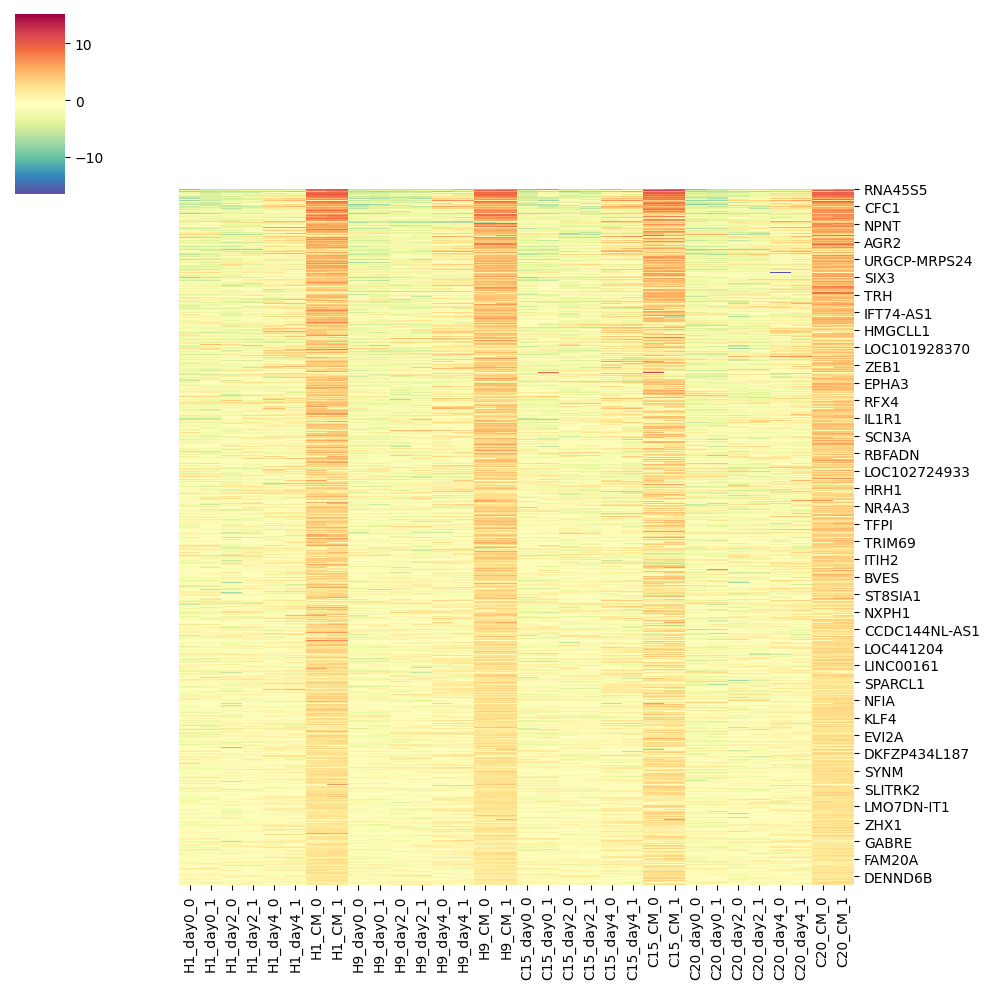

In [ ]:
sb.clustermap(Cluster0, row_cluster=False, col_cluster=False, cmap='Spectral_r')

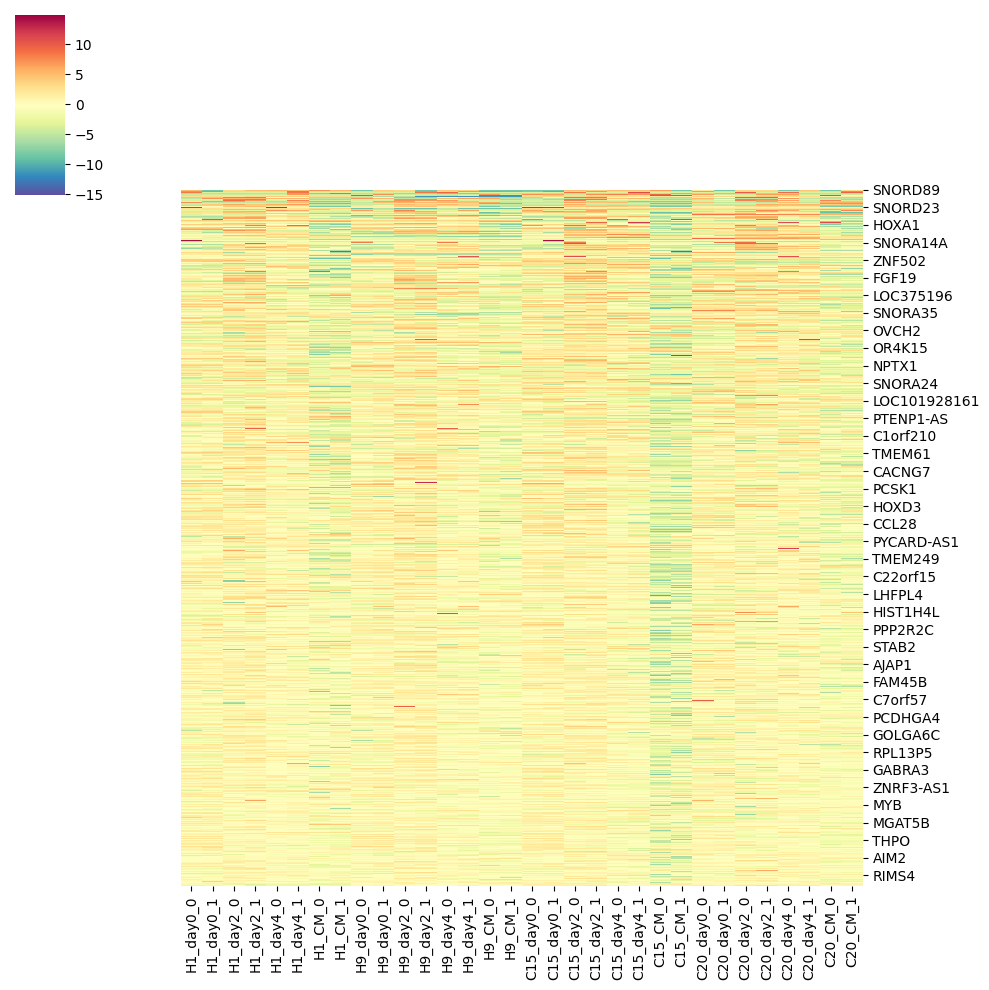

In [ ]:
sb.clustermap(Cluster1, cmap='Spectral_r', row_cluster=False, col_cluster=False)

> ✏️ *QUESTIONS:*
> -  Explain the results obtained and comment on the optimal number of clusters found.
> - Perform gene ontology overrepresentation analysis to identify the top ontologies for each cluster and comment on the results obtained.

⭐ *Hint*

To perform gene ontology over-representation follow the next steps:
> - Check the .csv file that was automatically saved in the _Resources folder;
> - Extract the gene names for each cluster;
> - Go to the GeneOntology website (https://www.geneontology.org/);
> - Paste the gene names on the GO Enrichment Analysis window;
> - Select the Biological Process Option and the organism Homo Sapiens and run.


Your answer goes here...

## <span style="color:#00aba1;"> 3.4. Evidence Accumulation</span>

In [ ]:
EAC=consensus_kmeans(Data, k=0)

/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:143: SparseEfficiencyWarning:

Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.



In [ ]:
EAC[0]

{0: array([  13,  358,  472,  490,  515,  669,  700,  774,  852,  884,  905,
        1034, 1068, 1131, 1250, 1255, 1350, 1357, 1372, 1437, 1511, 1527,
        1594, 1640, 1665, 1724, 1728, 1729, 1753, 1805, 1884, 1907, 1916,
        1965, 1966, 2077, 2134, 2161, 2198, 2246, 2264, 2273, 2286, 2289,
        2343, 2399, 2403, 2411, 2432, 2437, 2514, 2529, 2530, 2538, 2563,
        2597, 2651, 2732, 2748, 2774, 2816, 2827, 2864, 2890, 2891, 2907,
        2927, 2941, 2947, 2955, 2977, 2987, 3024, 3035, 3060, 3138, 3144,
        3148, 3155, 3236, 3356, 3383, 3385, 3414, 3483, 3521, 3559, 3618,
        3666, 3677, 3681, 3735, 3759, 3804, 3839, 3857, 3895, 3918, 3964,
        3979, 4023, 4079, 4089, 4109, 4154, 4167, 4200, 4239, 4305]),
 1: array([   6,   63,  167,  242,  259,  267,  368,  410,  473,  492,  552,
         595,  639,  871,  913, 1012, 1054, 1222, 1234, 1236, 1380, 1993,
        2202, 2375, 2379, 3471]),
 2: array([  25,  195,  250,  278,  306,  377,  469,  524,  658,  677,  702,

⭐ *Hint*

To visualize the obtained clusters, save the corresponding .csv file run the next cells chaging the cluster number

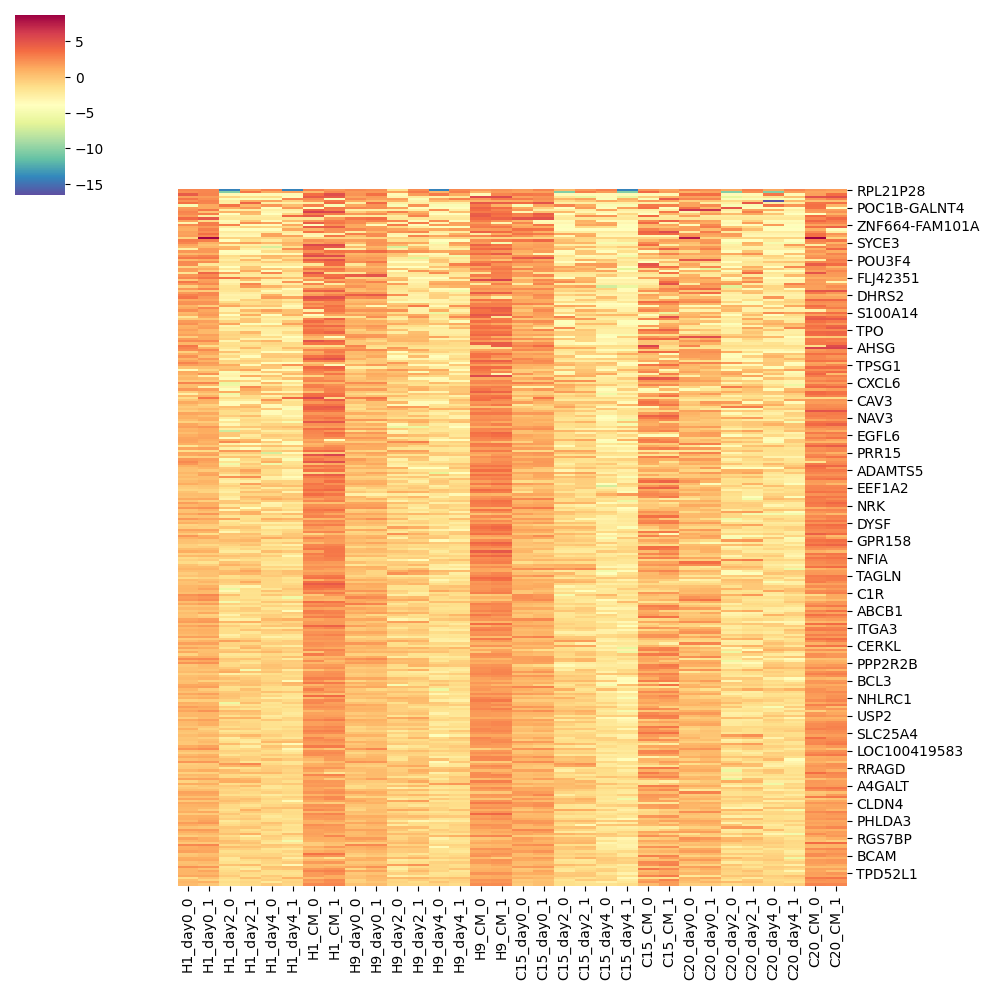

In [ ]:
# Plot Cluster 1
EACx=Data.iloc[EAC[0][x]]
sb.clustermap(EACx, row_cluster=False, col_cluster=False, cmap='Spectral_r')

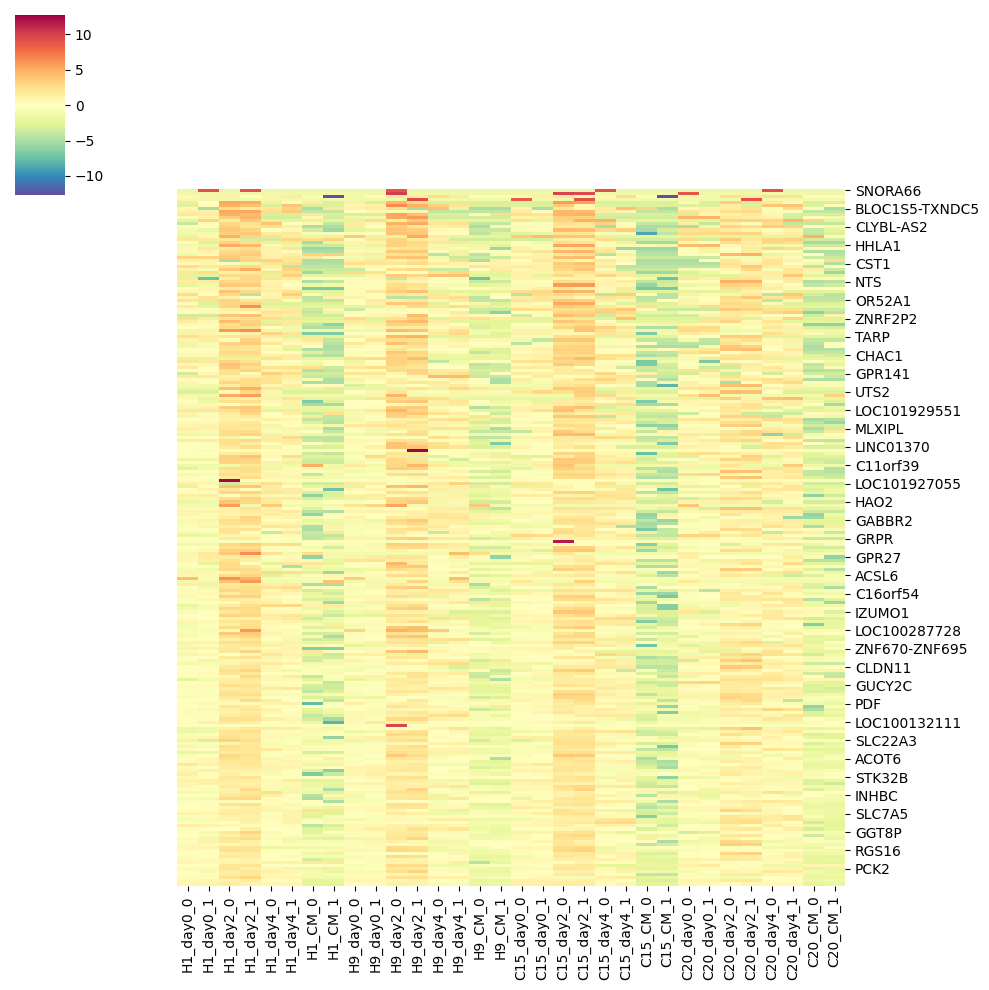

In [ ]:
# Plot Cluster 0
EAC29=Data.iloc[EAC[0][29]]
sb.clustermap(EAC29, row_cluster=False, col_cluster=False, cmap='Spectral_r')

In [ ]:
# Save Cluster 0
EACx.to_csv('/content/drive/MyDrive/Colab Notebooks/_Resources/EAC_x.csv')

> ✏️ *QUESTIONS:*
> - Comment on the results obtained and analyse the top ontologies for clusters that seam relevant.
> - Compare this set of clusters with the ones obtained with K-Means alone.

# <span style="color:#00aba1;"> Further Reading </span>

* The dataset used for this class is part of a published work that you can find here: Liu, Q., Jiang, C., Xu, J., Zhao, M. T., van Bortle, K., Cheng, X., Wang, G., Chang, H. Y., Wu, J. C., & Snyder, M. P. (2017). Genome-Wide Temporal Profiling of Transcriptome and Open Chromatin of Early Cardiomyocyte Differentiation Derived from hiPSCs and hESCs. Circulation Research, 121(4), 376–391. https://doi.org/10.1161/CIRCRESAHA.116.310456

* [1] Burridge, P. W., Keller, G., Gold, J. D., & Wu, J. C. (2012). Production of De Novo Cardiomyocytes: Human Pluripotent Stem Cell Differentiation and Direct Reprogramming. Cell Stem Cell, 10(1), 16–28. https://doi.org/10.1016/j.stem.2011.12.013
* [2] Kempf, H., Andree, B., & Zweigerdt, R. (2016). Large-scale production of human pluripotent stem cell derived cardiomyocytes. Advanced Drug Delivery Reviews, 96, 18–30. https://doi.org/10.1016/j.addr.2015.11.016
* [3]Fred, A. L. N., & Jain, A. K. (2005). Combining multiple clusterings using evidence accumulation. IEEE Transactions on Pattern Analysis and Machine Intelligence, 27(6), 835–850. https://doi.org/10.1109/TPAMI.2005.113

* D’haeseleer, P. (2005). How does gene expression clustering work ? Nature Biotechnology, 23(12), 1499–1501.
* Oyelade, J., Isewon, I., Oladipupo, F., Aromolaran, O., Uwoghiren, E., Ameh, F., Achas, M., & Adebiyi, E. (2016). Clustering Algorithms: Their Application to Gene Expression Data. Bioinformatics and Biology Insights, 10, BBI.S38316. https://doi.org/10.4137/BBI.S38316

<div style="width: 100%; ">
<div style="background:#00a0e4;color:white;font-family:'arial', monospace; text-align: center; padding: 50px 0; border-radius:10px; height:10px; width:100%; float:left " >
<span style="font-size:17px;position:relative; top:-20px"> Hope you enjoy this lab! </span>
<br>
<span style="font-size:12px;position:relative; top:-25px"> For any questions, email me at: sofia.p.agostinho@tecnico.ulisboa.pt <span style="font-size:14px;position:relative;COLOR:WHITE"> </span></span>
</div>
    
    

![scientisst-notebooks_bottom-banner](https://raw.githubusercontent.com/scientisst/notebooks/master/_Resources/bottom-banner.png)